# Student Performance Analysis
**End-to-end data analytics notebook** - Python | Pandas | NumPy | Matplotlib | Seaborn | SciPy

**Business problem:** Which factors drive student performance, and which students need academic support?

**Workflow:** Load -> Inspect -> Clean -> Feature engineering -> EDA -> Statistics & correlation -> Outliers -> Visualisation -> Export

> Run from the `notebooks/` folder. Paths are relative to the project root (`..`).

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent                       # project root (notebook lives in /notebooks)
RAW_PATH = ROOT / "data" / "raw" / "student_performance_raw.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
PASS_MARK = 40                                  # final marks >= 40 -> Pass
MAX_STUDY_HOURS = 20                            # > 20 hrs/week for one subject = data-entry error
NUM_COLS = ["Attendance", "Study_Hours", "Assignment_Marks", "Exam_Marks", "Final_Marks"]

## 2. Load data

In [2]:
df_raw = pd.read_csv(RAW_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (1140, 10)


,Student_ID,Gender,Age,Class,Subject,Attendance,Study_Hours,Assignment_Marks,Exam_Marks,Final_Marks
0,S1158,Female,16,Grade 11,History,85.1,9.3,73.8,67.6,69.44
1,S1181,Male,18,Grade 12,Computer Science,73.2,4.4,50.8,45.6,47.18
2,S1058,Male,16,Grade 11,Computer Science,91.9,13.0,91.3,78.6,82.41
3,S1209,Female,14,Grade 9,Mathematics,70.9,4.2,51.7,38.3,42.29
4,S1067,Female,18,Grade 12,English,84.1,11.0,90.2,74.2,79.00


## 3. Data quality inspection
Check data types, missing values, duplicates and unrealistic values before touching the data.

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1140 entries, 0 to 1139
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Student_ID        1140 non-null   str    
 1   Gender            1129 non-null   str    
 2   Age               1140 non-null   int64  
 3   Class             1140 non-null   str    
 4   Subject           1140 non-null   str    
 5   Attendance        1105 non-null   float64
 6   Study_Hours       1106 non-null   float64
 7   Assignment_Marks  1107 non-null   float64
 8   Exam_Marks        1107 non-null   float64
 9   Final_Marks       1117 non-null   float64
dtypes: float64(5), int64(1), str(4)
memory usage: 89.2 KB


In [4]:
missing = df_raw.isna().sum()
print("Missing values per column:")
print(missing[missing > 0])
print("\nTotal missing cells:", int(missing.sum()))
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
df_raw.describe().round(2)

Missing values per column:
Gender              11
Attendance          35
Study_Hours         34
Assignment_Marks    33
Exam_Marks          33
Final_Marks         23
dtype: int64

Total missing cells: 169
Exact duplicate rows: 40


,Age,Attendance,Study_Hours,Assignment_Marks,Exam_Marks,Final_Marks
count,1140.00,1105.00,1106.00,1107.00,1107.00,1117.00
mean,15.71,81.96,6.28,62.77,56.75,58.57
std,1.21,8.69,3.91,11.77,14.49,12.78
min,14.00,58.00,0.50,30.40,14.10,20.32
25%,15.00,76.10,4.00,54.60,46.70,49.81
50%,16.00,81.90,6.10,62.50,56.90,58.41
75%,17.00,87.90,8.17,70.90,66.50,67.54
max,18.00,100.00,60.00,100.00,100.00,99.13


**Observation:** `Study_Hours` has a maximum far above what is possible for one subject (data-entry errors), and there are duplicate rows and missing values in several columns.

## 4. Data cleaning

### 4.1 Standardise text and remove duplicates

In [5]:
df = df_raw.copy()

for c in ["Student_ID", "Gender", "Class", "Subject"]:
    df[c] = df[c].astype("string").str.strip()          # remove stray whitespace
df["Gender"] = df["Gender"].str.title()

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)} -> {len(df)} rows remain")

Duplicates removed: 40 -> 1100 rows remain


### 4.2 Outlier detection (IQR rule) before treatment

In [6]:
def detect_outliers_iqr(data, cols=NUM_COLS):
    """Count values outside Q1 - 1.5*IQR and Q3 + 1.5*IQR for each column."""
    rows = []
    for c in cols:
        s = data[c].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((s < low) | (s > high)).sum())
        rows.append({"Column": c, "Q1": q1, "Q3": q3, "IQR": iqr, "Lower_Fence": low,
                     "Upper_Fence": high, "Outliers": n, "Outlier_%": round(100 * n / len(s), 2)})
    return pd.DataFrame(rows).round(2)

detect_outliers_iqr(df)

,Column,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Outliers,Outlier_%
0,Attendance,76.10,87.95,11.85,58.32,105.73,2,0.19
1,Study_Hours,4.00,8.10,4.10,-2.15,14.25,9,0.84
2,Assignment_Marks,54.60,70.85,16.25,30.23,95.22,4,0.37
3,Exam_Marks,46.70,66.40,19.70,17.15,95.95,7,0.66
4,Final_Marks,49.84,67.45,17.61,23.43,93.87,6,0.56


### 4.3 Treat impossible values
Study hours above 20 per week for a single subject are treated as errors and set to missing (they are imputed in the next step). Marks and attendance must be within 0-100.

In [7]:
bad_hours = df["Study_Hours"] > MAX_STUDY_HOURS
print("Invalid Study_Hours:", int(bad_hours.sum()))
df.loc[bad_hours, "Study_Hours"] = np.nan

for c in ["Attendance", "Assignment_Marks", "Exam_Marks", "Final_Marks"]:
    df[c] = df[c].where(df[c].between(0, 100))

Invalid Study_Hours: 6


### 4.4 Missing value treatment
| Column | Strategy | Why |
|---|---|---|
| Gender | Copy from the same student's other records | Gender is a student attribute |
| Attendance | Student's mean attendance, else overall median | Attendance is mostly a student habit |
| Study_Hours, Assignment_Marks, Exam_Marks | Median of the same subject | Median is robust to outliers |
| Final_Marks | Recompute = 0.30 x Assignment + 0.70 x Exam | It is a derived column |

In [8]:
df["Gender"] = df.groupby("Student_ID")["Gender"].transform(
    lambda s: s.fillna(s.dropna().iloc[0]) if s.notna().any() else s)
df["Gender"] = df["Gender"].fillna("Unknown")

df["Attendance"] = df["Attendance"].fillna(df.groupby("Student_ID")["Attendance"].transform("mean"))
df["Attendance"] = df["Attendance"].fillna(df["Attendance"].median())

for c in ["Study_Hours", "Assignment_Marks", "Exam_Marks"]:
    df[c] = df[c].fillna(df.groupby("Subject")[c].transform("median"))

df["Final_Marks"] = (0.30 * df["Assignment_Marks"] + 0.70 * df["Exam_Marks"]).round(2)
df[["Attendance", "Study_Hours", "Assignment_Marks", "Exam_Marks"]] = \
    df[["Attendance", "Study_Hours", "Assignment_Marks", "Exam_Marks"]].round(1)
df["Age"] = df["Age"].astype(int)

print("Missing values remaining:", int(df.isna().sum().sum()))

Missing values remaining: 0


### 4.5 Feature engineering
Create result, grade, performance category and bands used later by SQL and Power BI.

In [9]:
df["Pass_Fail"] = np.where(df["Final_Marks"] >= PASS_MARK, "Pass", "Fail")
df["Grade"] = pd.cut(df["Final_Marks"], bins=[-0.01, 39.99, 49.99, 59.99, 69.99, 79.99, 100],
                     labels=["F", "E", "D", "C", "B", "A"]).astype(str)
df["Performance_Category"] = pd.cut(df["Final_Marks"], bins=[-0.01, 49.99, 64.99, 79.99, 100],
                                    labels=["At Risk", "Average", "Good", "Excellent"]).astype(str)
df["Attendance_Band"] = pd.cut(df["Attendance"], bins=[0, 60, 75, 90, 100.01], right=False,
                               labels=["<60%", "60-75%", "75-90%", "90-100%"]).astype(str)
df["Study_Band"] = pd.cut(df["Study_Hours"], bins=[0, 4, 8, 12, 100],
                          labels=["0-4 hrs", "4-8 hrs", "8-12 hrs", "12+ hrs"]).astype(str)
print("Cleaned shape:", df.shape)
df.head()

Cleaned shape: (1100, 15)


,Student_ID,Gender,Age,Class,Subject,Attendance,Study_Hours,Assignment_Marks,Exam_Marks,Final_Marks,Pass_Fail,Grade,Performance_Category,Attendance_Band,Study_Band
0,S1158,Female,16,Grade 11,History,85.1,9.3,73.8,67.6,69.46,Pass,C,Good,75-90%,8-12 hrs
1,S1181,Male,18,Grade 12,Computer Science,73.2,4.4,50.8,45.6,47.16,Pass,E,At Risk,60-75%,4-8 hrs
2,S1058,Male,16,Grade 11,Computer Science,91.9,13.0,91.3,78.6,82.41,Pass,A,Excellent,90-100%,12+ hrs
3,S1209,Female,14,Grade 9,Mathematics,70.9,4.2,51.7,38.3,42.32,Pass,E,At Risk,60-75%,4-8 hrs
4,S1067,Female,18,Grade 12,English,84.1,11.0,90.2,74.2,79.00,Pass,B,Good,75-90%,8-12 hrs


## 5. Exploratory data analysis

In [10]:
df[NUM_COLS].describe().round(2)

,Attendance,Study_Hours,Assignment_Marks,Exam_Marks,Final_Marks
count,1100.00,1100.00,1100.00,1100.00,1100.00
mean,82.02,6.09,62.72,56.76,58.55
std,8.65,2.81,11.53,14.20,12.41
min,58.00,0.50,30.40,14.10,20.34
25%,76.20,4.10,54.70,47.08,50.07
50%,81.95,6.10,62.50,57.35,58.50
75%,88.00,8.00,70.62,66.30,67.19
max,100.00,15.90,100.00,100.00,99.13


In [11]:
total = len(df)
print(f"Students: {df.Student_ID.nunique()} | Records: {total}")
print(f"Average final marks : {df.Final_Marks.mean():.2f}")
print(f"Pass percentage     : {(df.Pass_Fail == 'Pass').mean() * 100:.2f}%")
print(f"Average attendance  : {df.Attendance.mean():.2f}%")
print(f"Avg weekly study hrs: {df.Study_Hours.mean():.2f}")

Students: 220 | Records: 1100
Average final marks : 58.55
Pass percentage     : 92.64%
Average attendance  : 82.02%
Avg weekly study hrs: 6.09


### Performance by subject

In [12]:
by_subject = (df.groupby("Subject")
                .agg(Avg_Final=("Final_Marks", "mean"), Avg_Exam=("Exam_Marks", "mean"),
                     Avg_Assignment=("Assignment_Marks", "mean"),
                     Pass_Rate=("Pass_Fail", lambda s: (s == "Pass").mean() * 100))
                .round(2).sort_values("Avg_Final", ascending=False))
by_subject

,Avg_Final,Avg_Exam,Avg_Assignment,Pass_Rate
Subject,,,,
English,61.42,59.51,65.86,95.45
Computer Science,60.19,58.35,64.47,94.55
History,59.73,58.28,63.11,92.73
Science,57.20,55.22,61.82,91.36
Mathematics,54.22,52.44,58.35,89.09


### Performance by class and gender

In [13]:
by_class = (df.groupby("Class")
              .agg(Students=("Student_ID", "nunique"), Avg_Final=("Final_Marks", "mean"),
                   Pass_Rate=("Pass_Fail", lambda s: (s == "Pass").mean() * 100))
              .round(2).sort_values("Avg_Final", ascending=False))
by_class

,Students,Avg_Final,Pass_Rate
Class,,,
Grade 10,58,60.63,96.21
Grade 11,61,58.91,92.13
Grade 9,58,57.77,91.38
Grade 12,43,56.28,90.23


In [14]:
(df[df.Gender != "Unknown"].groupby("Gender")
   .agg(Avg_Final=("Final_Marks", "mean"), Pass_Rate=("Pass_Fail", lambda s: (s == "Pass").mean() * 100))
   .round(2))

,Avg_Final,Pass_Rate
Gender,,
Female,58.92,92.04
Male,58.22,93.16


### Does attendance matter? Does study time matter?

In [15]:
att_order = ["<60%", "60-75%", "75-90%", "90-100%"]
study_order = ["0-4 hrs", "4-8 hrs", "8-12 hrs", "12+ hrs"]
display_att = df.groupby("Attendance_Band").agg(Avg_Final=("Final_Marks", "mean"), Records=("Final_Marks", "size")).round(2).reindex(att_order)
display_study = df.groupby("Study_Band").agg(Avg_Exam=("Exam_Marks", "mean"), Records=("Exam_Marks", "size")).round(2).reindex(study_order)
print(display_att, "\n")
print(display_study)

                 Avg_Final  Records
Attendance_Band                    
<60%                 48.90        7
60-75%               52.94      223
75-90%               58.84      668
90-100%              64.12      202 

            Avg_Exam  Records
Study_Band                   
0-4 hrs        50.07      268
4-8 hrs        56.48      565
8-12 hrs       62.72      242
12+ hrs        77.12       25


## 6. Statistical & correlation analysis

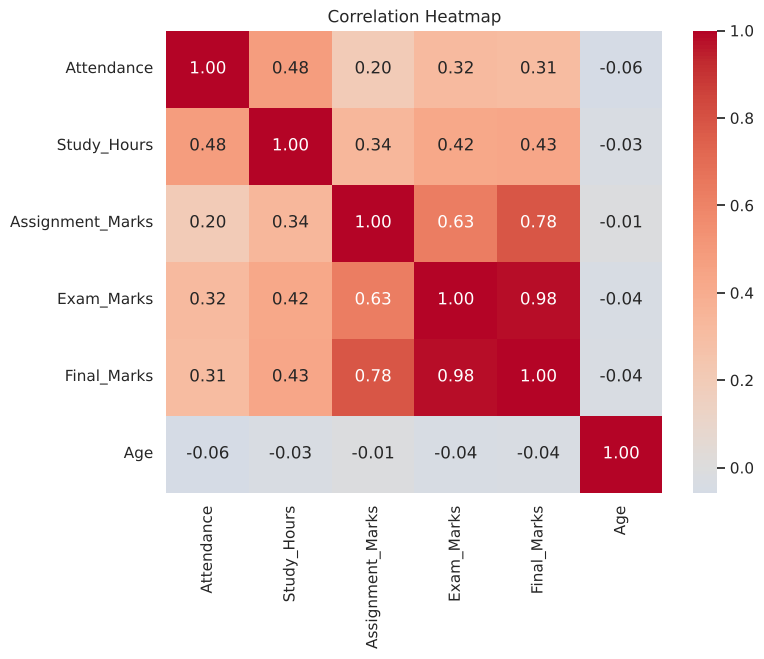

In [16]:
corr = df[NUM_COLS + ["Age"]].corr().round(3)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [17]:
for x, y in [("Attendance", "Final_Marks"), ("Study_Hours", "Exam_Marks")]:
    r, p = stats.pearsonr(df[x], df[y])
    rho, p_s = stats.spearmanr(df[x], df[y])
    print(f"{x:12s} vs {y:12s} | Pearson r = {r:.3f} (p = {p:.1e}) | Spearman rho = {rho:.3f}")

slope = stats.linregress(df["Study_Hours"], df["Exam_Marks"]).slope
print(f"\nEach extra weekly study hour is associated with {slope:.2f} more exam marks")

f_stat, p_anova = stats.f_oneway(*[g.Final_Marks.values for _, g in df.groupby("Subject")])
print(f"ANOVA across subjects: F = {f_stat:.2f}, p = {p_anova:.1e}  -> subjects differ significantly")

g = df[df.Gender.isin(["Male", "Female"])]
t, p_t = stats.ttest_ind(g[g.Gender == "Male"].Final_Marks, g[g.Gender == "Female"].Final_Marks, equal_var=False)
print(f"Welch t-test (gender): t = {t:.2f}, p = {p_t:.3f}  -> no significant gender difference")

Attendance   vs Final_Marks  | Pearson r = 0.311 (p = 4.2e-26) | Spearman rho = 0.306
Study_Hours  vs Exam_Marks   | Pearson r = 0.423 (p = 6.6e-49) | Spearman rho = 0.391

Each extra weekly study hour is associated with 2.13 more exam marks
ANOVA across subjects: F = 12.22, p = 1.0e-09  -> subjects differ significantly
Welch t-test (gender): t = -0.93, p = 0.352  -> no significant gender difference


## 7. Outlier detection after cleaning

In [18]:
detect_outliers_iqr(df)

,Column,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Outliers,Outlier_%
0,Attendance,76.20,88.00,11.80,58.50,105.70,2,0.18
1,Study_Hours,4.10,8.00,3.90,-1.75,13.85,4,0.36
2,Assignment_Marks,54.70,70.62,15.92,30.81,94.51,6,0.55
3,Exam_Marks,47.08,66.30,19.22,18.24,95.14,9,0.82
4,Final_Marks,50.07,67.19,17.12,24.39,92.87,7,0.64


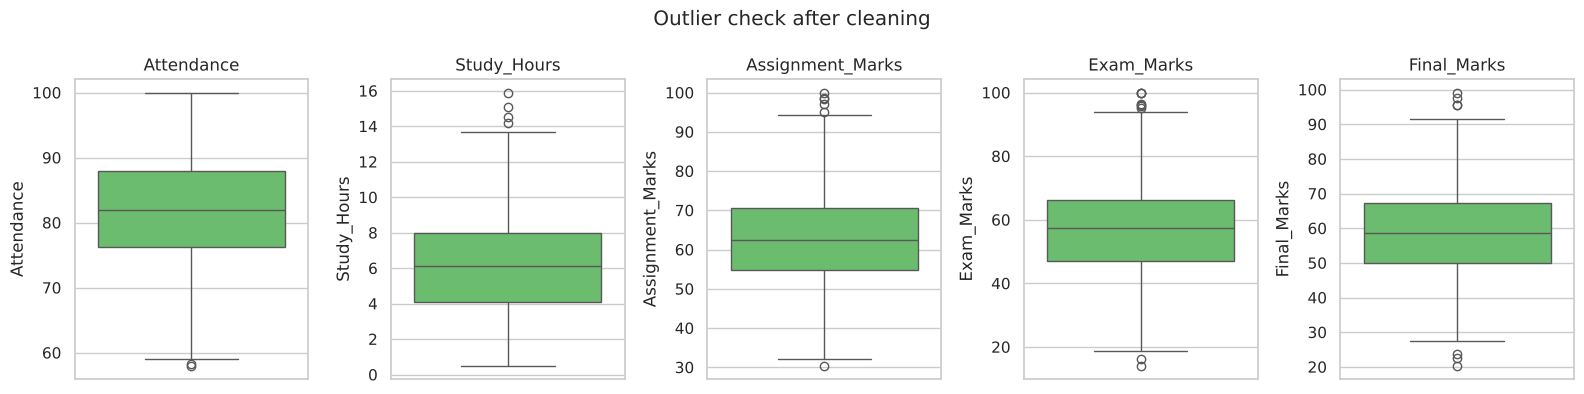

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, c in zip(axes, NUM_COLS):
    sns.boxplot(y=df[c], ax=ax, color="#5ec962")
    ax.set_title(c)
plt.suptitle("Outlier check after cleaning")
plt.tight_layout()
plt.show()

The remaining IQR outliers are genuine low/high scores (not impossible values), so they are **kept**.

## 8. Visualisation

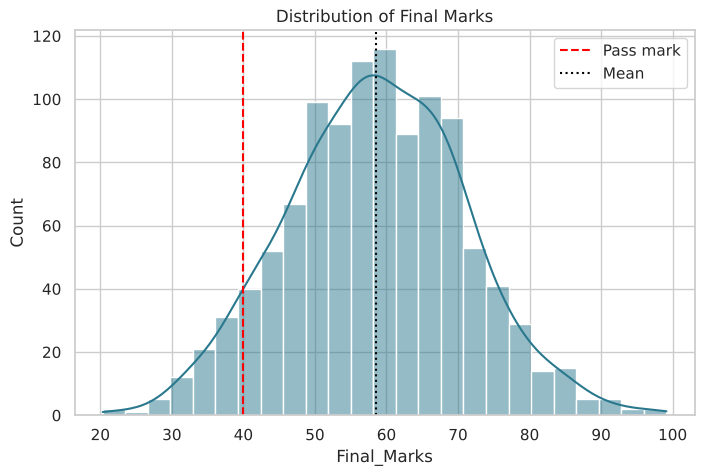

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["Final_Marks"], bins=25, kde=True, color="#2a788e", ax=ax)
ax.axvline(PASS_MARK, color="red", ls="--", label="Pass mark")
ax.axvline(df["Final_Marks"].mean(), color="black", ls=":", label="Mean")
ax.set(title="Distribution of Final Marks"); ax.legend()
plt.show()

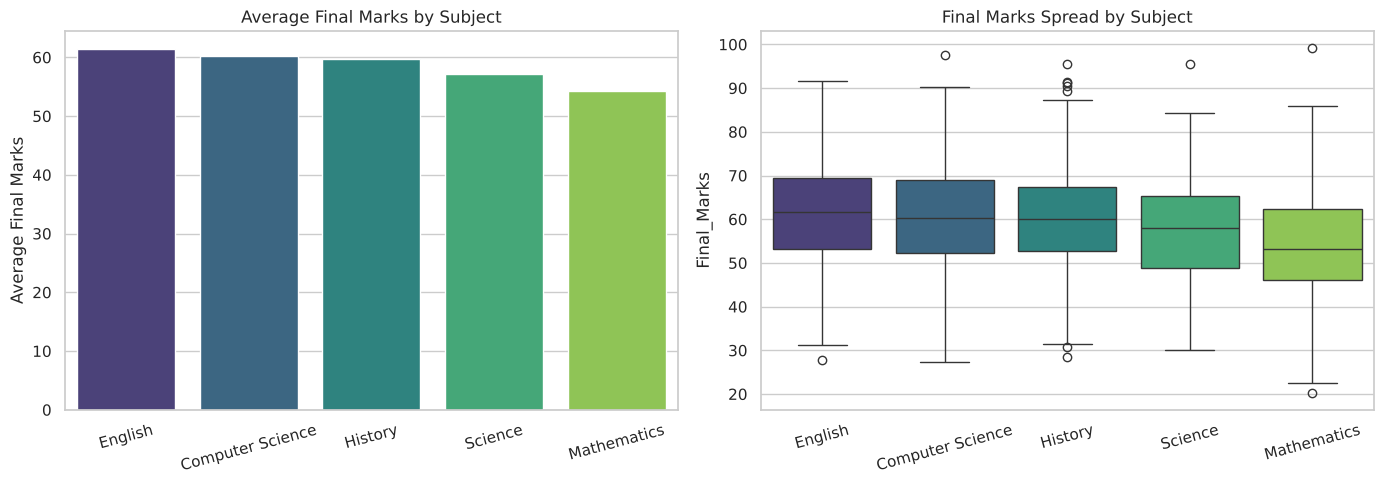

In [21]:
order = df.groupby("Subject")["Final_Marks"].mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=order.index, y=order.values, palette="viridis", ax=axes[0])
axes[0].set(title="Average Final Marks by Subject", xlabel="", ylabel="Average Final Marks")
axes[0].tick_params(axis="x", rotation=15)
sns.boxplot(data=df, x="Subject", y="Final_Marks", order=order.index, palette="viridis", ax=axes[1])
axes[1].set(title="Final Marks Spread by Subject", xlabel="")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

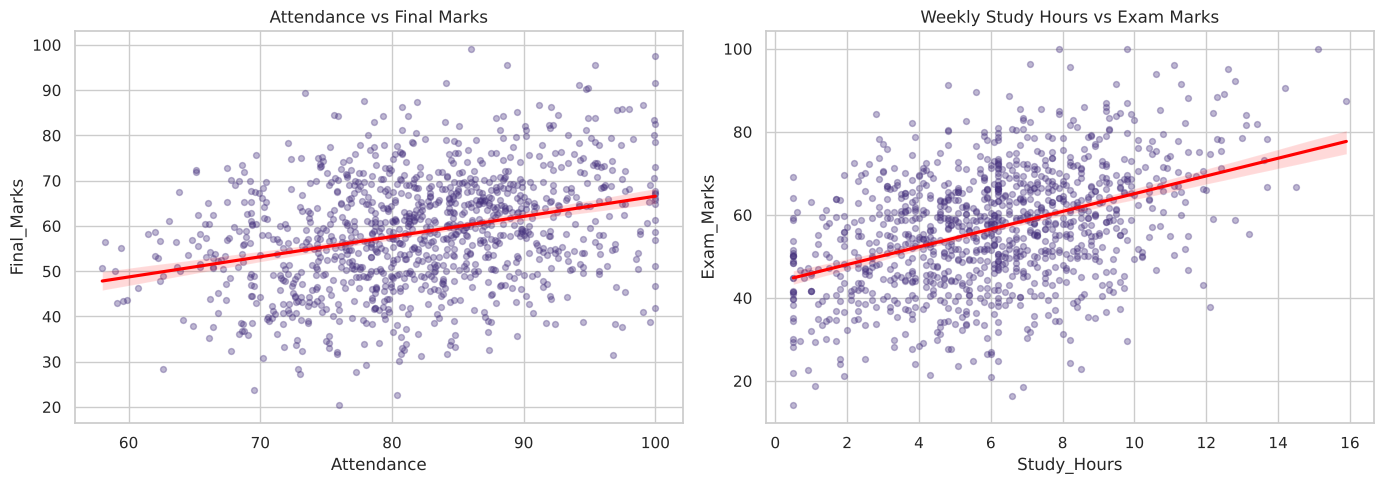

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=df, x="Attendance", y="Final_Marks", scatter_kws={"alpha": .35, "s": 18},
            line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("Attendance vs Final Marks")
sns.regplot(data=df, x="Study_Hours", y="Exam_Marks", scatter_kws={"alpha": .35, "s": 18},
            line_kws={"color": "red"}, ax=axes[1])
axes[1].set_title("Weekly Study Hours vs Exam Marks")
plt.tight_layout(); plt.show()

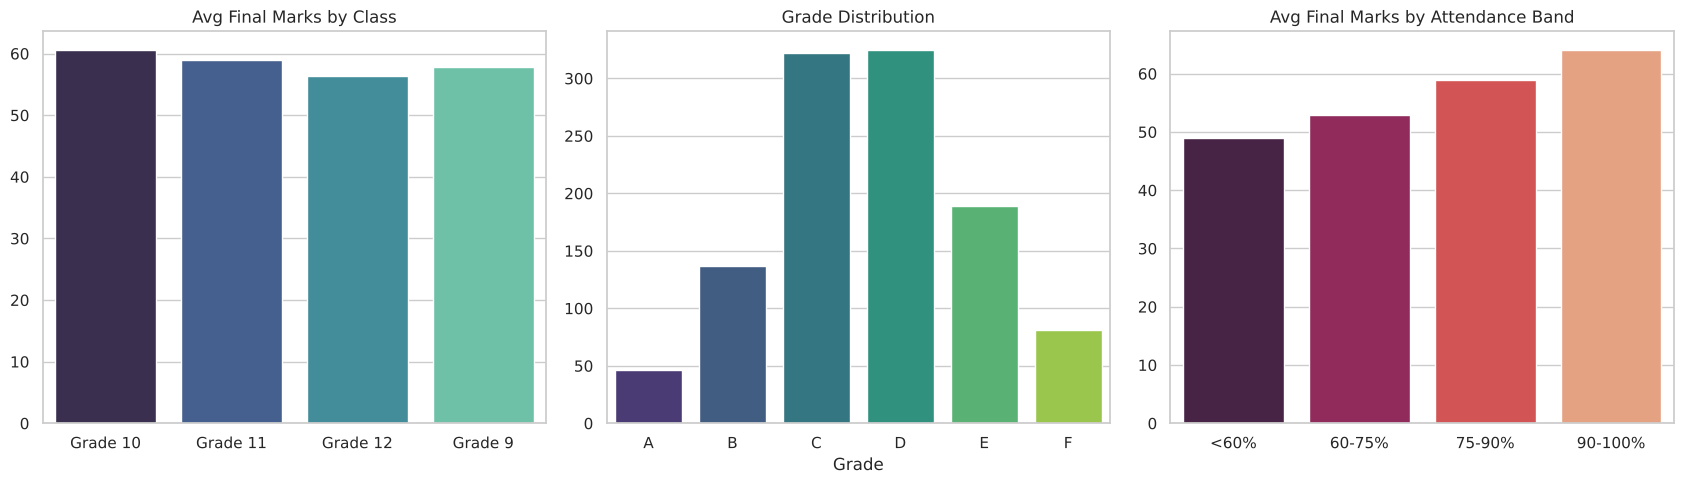

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
cls = df.groupby("Class")["Final_Marks"].mean().sort_index()
sns.barplot(x=cls.index, y=cls.values, palette="mako", ax=axes[0]); axes[0].set(title="Avg Final Marks by Class", xlabel="")
gd = df["Grade"].value_counts().reindex(["A", "B", "C", "D", "E", "F"]).fillna(0)
sns.barplot(x=gd.index, y=gd.values, palette="viridis", ax=axes[1]); axes[1].set(title="Grade Distribution", xlabel="Grade")
band = df.groupby("Attendance_Band")["Final_Marks"].mean().reindex(att_order)
sns.barplot(x=band.index, y=band.values, palette="rocket", ax=axes[2]); axes[2].set(title="Avg Final Marks by Attendance Band", xlabel="")
plt.tight_layout(); plt.show()

## 9. Which students need academic support?
Rule: **average < 50 OR failed 2+ subjects OR average attendance < 75%**.

In [24]:
student = df.groupby("Student_ID").agg(
    Class=("Class", "first"), Gender=("Gender", "first"),
    Avg_Final=("Final_Marks", "mean"), Avg_Attendance=("Attendance", "mean"),
    Avg_Study_Hours=("Study_Hours", "mean"),
    Subjects_Failed=("Pass_Fail", lambda s: int((s == "Fail").sum())))
student["Needs_Support"] = ((student.Avg_Final < 50) | (student.Subjects_Failed >= 2) | (student.Avg_Attendance < 75))
student[["Avg_Final", "Avg_Attendance", "Avg_Study_Hours"]] = student[["Avg_Final", "Avg_Attendance", "Avg_Study_Hours"]].round(2)

print(f"Students needing support: {student.Needs_Support.sum()} ({student.Needs_Support.mean() * 100:.2f}%)")
student[student.Needs_Support].sort_values("Avg_Final").head(10)

Students needing support: 70 (31.82%)


,Class,Gender,Avg_Final,Avg_Attendance,Avg_Study_Hours,Subjects_Failed,Needs_Support
Student_ID,,,,,,,
S1092,Grade 9,Female,30.09,81.56,4.92,5,True
S1192,Grade 10,Male,31.96,77.38,4.82,3,True
S1132,Grade 9,Male,36.34,76.14,2.22,4,True
S1156,Grade 9,Male,37.31,68.64,3.42,4,True
S1096,Grade 12,Female,37.91,77.48,6.86,4,True
S1042,Grade 12,Female,39.35,83.32,6.78,3,True
S1078,Grade 10,Female,39.42,76.64,1.52,4,True
S1066,Grade 12,Male,39.70,97.50,7.66,3,True
S1162,Grade 11,Male,40.62,69.58,3.64,2,True


## 10. Export cleaned data

In [25]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
export_cols = ["Student_ID", "Gender", "Age", "Class", "Subject", "Attendance", "Study_Hours",
               "Assignment_Marks", "Exam_Marks", "Final_Marks", "Grade", "Pass_Fail",
               "Performance_Category", "Attendance_Band", "Study_Band"]
df[export_cols].to_csv(PROCESSED_DIR / "student_performance_cleaned.csv", index=False)
print("Saved:", PROCESSED_DIR / "student_performance_cleaned.csv")

Saved: /home/claude/Student_Performance_Analysis/data/processed/student_performance_cleaned.csv


## 11. Conclusions
* **English** has the highest average marks (61.42); **Mathematics** is the weakest (54.22) in every class.
* **92.64%** of subject records are passes; **Grade 10** is the best class, **Grade 12** the weakest.
* **Attendance** (r = 0.31) and **weekly study time** (r = 0.42 with exam marks, about +2.1 marks per extra hour) both relate positively to performance.
* No significant gender difference (p = 0.35).
* **70 students (31.8%)** need academic support - see `reports/insights.md` for recommendations.